# Train model dự đoán "học sinh có làm đúng câu tiếp theo không"

Notebook này đi qua từng bước của quy trình trong sách **Hands-On Machine Learning** (Aurélien Géron, repo `ageron/handson-ml3`, chương 2–4), áp vào dữ liệu HarmonyMentor. Code thật nằm ở `backend/app/ml/correctness/`; notebook chỉ gọi lại để giải thích.

Chạy: `cd backend && pip install -r requirements.txt matplotlib jupyter && jupyter notebook ../notebooks/du_doan_dung_cau_tiep.ipynb`

> Dữ liệu ở đây là **người học mô phỏng**: kết quả chưa chứng minh chất lượng với người học thật.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../backend'))
import numpy as np
import matplotlib.pyplot as plt
from app.ml.correctness import dataset
from app.ml.correctness.features import FEATURE_NAMES, NUMERIC
from app.ml.correctness.train import build_matrix, metrics
np.set_printoptions(precision=3, suppress=True)

## Bước 1. Bài toán là gì?

Mỗi lần học sinh làm một câu (hoặc ôn một thẻ), ta muốn đoán **trước** khi họ trả lời: xác suất làm đúng là bao nhiêu?

Đây là bài toán **phân loại nhị phân** (đúng = 1, sai = 0), giống ví dụ "nhận diện chữ số 5" ở chương 3 của sách. Model trả ra xác suất, ví dụ 0,72 nghĩa là "khoảng 72% sẽ làm đúng".

In [2]:
# 600 người mô phỏng cho nhanh (bản chính thức trong báo cáo dùng 2.000 người)
events = dataset.sim_events(600, 20261119, with_true_p=True)
uid = sorted(events)[0]
for e in events[uid][:6]:
    print(e)

{'user': 'sim-00000', 't': 3484802, 'kind': 'attempt', 'skill': 'interval.naming', 'exercise': 'L01-Q01', 'correct': False, 'p_true': 0.4403208002506347}
{'user': 'sim-00000', 't': 3484803, 'kind': 'attempt', 'skill': 'interval.naming', 'exercise': 'L01-Q01', 'correct': False, 'p_true': 0.5087062242616703}
{'user': 'sim-00000', 't': 3484804, 'kind': 'attempt', 'skill': 'interval.naming', 'exercise': 'L01-Q01', 'correct': False, 'p_true': 0.7570272247440095}
{'user': 'sim-00000', 't': 3571205, 'kind': 'attempt', 'skill': 'interval.naming', 'exercise': 'L01-Q01', 'correct': True, 'p_true': 0.600454995120424}
{'user': 'sim-00000', 't': 3571206, 'kind': 'attempt', 'skill': 'chord.triad_build', 'exercise': 'L01-Q02', 'correct': False, 'p_true': 0.2570481863963571}
{'user': 'sim-00000', 't': 3571207, 'kind': 'attempt', 'skill': 'chord.triad_build', 'exercise': 'L01-Q02', 'correct': False, 'p_true': 0.2235097531174558}


## Bước 2. Biến lịch sử thành đặc trưng (feature)

Model không đọc được "lịch sử" thô, nên ta tính một hàng số cho mỗi lượt. Quy tắc quan trọng nhất: **chỉ dùng thông tin TRƯỚC lượt đó**. Nếu lỡ dùng kết quả của chính lượt đó (hay lượt sau), model sẽ "nhìn trộm đáp án" và số đo đẹp giả. Sách gọi đây là *data leakage*.

In [3]:
X, y, groups, p_true = build_matrix(events)
print(X.shape, '→', len(np.unique(groups)), 'người,', round(y.mean(), 3), 'tỷ lệ đúng')
for name, v in zip(NUMERIC, X[5][:len(NUMERIC)]):
    print(f'{name:16s} {v:.3f}')

(48491, 28) → 600 người, 0.561 tỷ lệ đúng
ema_skill        0.000
seen_skill       1.000
log_n_skill      0.693
acc_skill        0.333
last_skill       0.000
tries_exercise   1.000
last_ex_wrong    1.000
is_review        0.000
log_gap_days     0.000
acc_user         0.286
log_n_user       1.792
ema_group        0.000
prereq_ema       0.000


## Bước 3. Chia train/test THEO NGƯỜI HỌC

Sách (chương 2) nhắc: phải để riêng một tập test và **không nhìn vào nó** cho tới cuối. Ở đây một người có nhiều lượt; nếu chia ngẫu nhiên theo lượt, các lượt của cùng một người nằm ở cả hai bên, và model "nhớ" người đó thay vì học quy luật. Ta dùng `GroupShuffleSplit`: một người nằm trọn ở train hoặc trọn ở test.

In [4]:
from sklearn.model_selection import GroupShuffleSplit
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=1).split(X, y, groups))
print('train', len(tr), 'lượt /', len(set(groups[tr])), 'người;  test', len(te), 'lượt /', len(set(groups[te])), 'người')
print('người chung hai bên:', len(set(groups[tr]) & set(groups[te])))

train 38830 lượt / 480 người;  test 9661 lượt / 120 người
người chung hai bên: 0


## Bước 4. Baseline: cách đơn giản nhất làm được bao nhiêu?

Trước khi train, phải có mốc so sánh. Nếu model không hơn mốc này thì không đáng dùng.
- **mastery EMA**: dùng luôn điểm mastery hiện có của app làm xác suất.
- **Trần lý thuyết**: vì là mô phỏng, ta biết xác suất thật bộ mô phỏng dùng để tung. Không model nào vượt được mức này.

**AUC** (chương 3): chọn ngẫu nhiên một lượt đúng và một lượt sai, AUC là xác suất model cho lượt đúng điểm cao hơn. 0,5 = đoán mò, 1,0 = hoàn hảo.

In [5]:
col = {n: i for i, n in enumerate(FEATURE_NAMES)}
for name, p in [('hằng số', np.full(len(te), y[tr].mean())), ('mastery EMA', X[te, col['ema_skill']]),
                ('trần lý thuyết', p_true[te])]:
    r = metrics(y[te], p)
    print(f"{name:15s} AUC {r['auc']:.3f}   log loss {r['log_loss']:.3f}   ECE {r['ece']:.3f}")

hằng số         AUC 0.500   log loss 0.687   ECE 0.008
mastery EMA     AUC 0.589   log loss 2.349   ECE 0.311
trần lý thuyết  AUC 0.678   log loss 0.635   ECE 0.007


## Bước 5. Pipeline + GridSearchCV

`Pipeline` gói "chuẩn hóa → model" thành một khối (chương 2), để lúc phục vụ API chỉ cần `pipeline.predict_proba(X)`.
`GridSearchCV` thử từng giá trị tham số (ví dụ `C` của Logistic Regression), mỗi giá trị chấm bằng kiểm chéo 3 phần **theo người học** (`GroupKFold`), rồi chọn giá trị tốt nhất. Tập test vẫn chưa bị đụng tới.

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, GroupKFold

lr = Pipeline([('scale', StandardScaler()), ('model', LogisticRegression(max_iter=2000))])
search = GridSearchCV(lr, {'model__C': [0.01, 0.1, 1, 10]}, scoring='roc_auc', cv=GroupKFold(3))
search.fit(X[tr], y[tr], groups=groups[tr])
for prm, s in zip(search.cv_results_['params'], search.cv_results_['mean_test_score']):
    print(prm, round(s, 4))

hgb = HistGradientBoostingClassifier(early_stopping=False, max_depth=3, learning_rate=0.05, max_iter=150, random_state=1)
hgb.fit(X[tr], y[tr])
for name, model in [('Logistic Regression', search.best_estimator_), ('HistGradientBoosting', hgb)]:
    r = metrics(y[te], model.predict_proba(X[te])[:, 1])
    print(f"{name:21s} AUC {r['auc']:.3f}  Precision {r['precision']:.3f}  Recall {r['recall']:.3f}  ECE {r['ece']:.3f}")

{'model__C': 0.01} 0.6282
{'model__C': 0.1} 0.6282
{'model__C': 1} 0.6282
{'model__C': 10} 0.6282


Logistic Regression   AUC 0.616  Precision 0.607  Recall 0.764  ECE 0.013
HistGradientBoosting  AUC 0.617  Precision 0.609  Recall 0.756  ECE 0.012


## Bước 6. Precision, Recall và ma trận nhầm lẫn

Lấy ngưỡng 0,5: xác suất ≥ 0,5 thì đoán "sẽ đúng".
- **Precision**: trong các lượt model đoán "đúng", bao nhiêu % thật sự đúng.
- **Recall**: trong các lượt thật sự đúng, model bắt được bao nhiêu %.

In [7]:
from sklearn.metrics import confusion_matrix
p = search.best_estimator_.predict_proba(X[te])[:, 1]
print(confusion_matrix(y[te], (p >= 0.5).astype(int)))
print('hàng = thật (sai, đúng), cột = đoán (sai, đúng)')

[[1645 2656]
 [1264 4096]]
hàng = thật (sai, đúng), cột = đoán (sai, đúng)


## Bước 7. Xác suất có "thật thà" không? (độ hiệu chỉnh)

Nếu model nói 70% thì trong các lượt đó phải có khoảng 70% đúng. Đường càng sát đường chéo càng tốt. Để ý EMA: điểm 0 không có nghĩa là "chắc chắn sai", nên EMA rất lệch nếu dùng làm xác suất.

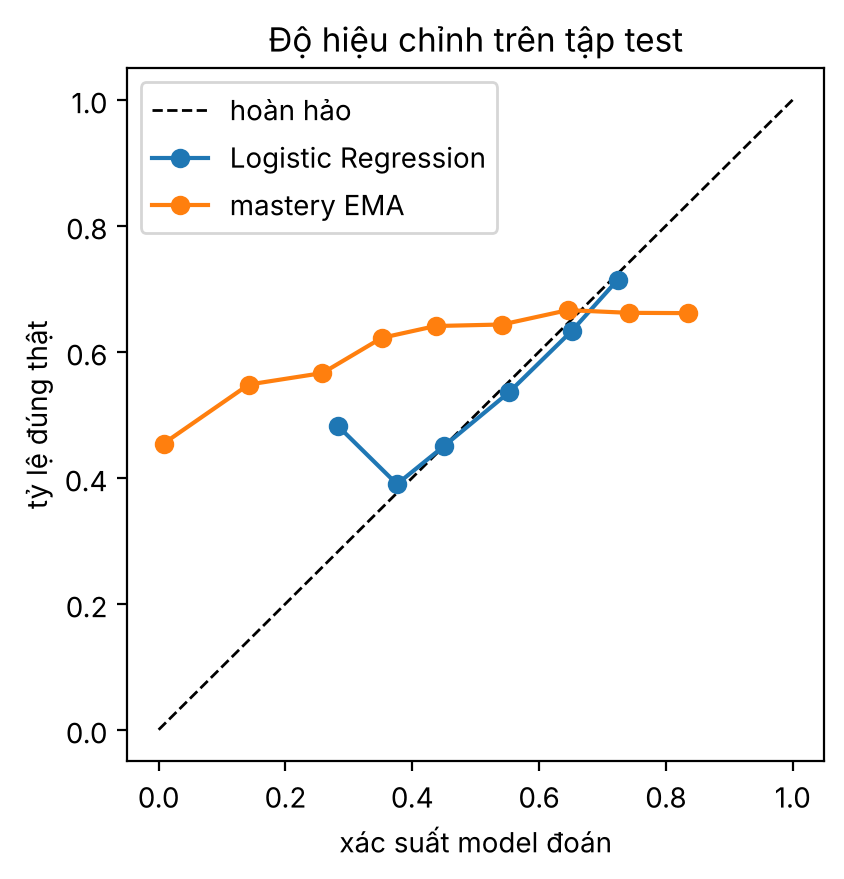

In [8]:
def reliability(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1); idx = np.clip(np.digitize(p, edges[1:-1]), 0, bins - 1)
    xs = [p[idx == b].mean() for b in range(bins) if (idx == b).any()]
    ys = [y[idx == b].mean() for b in range(bins) if (idx == b).any()]
    return xs, ys
plt.figure(figsize=(4.5, 4.5))
plt.plot([0, 1], [0, 1], 'k--', lw=1, label='hoàn hảo')
for name, pp in [('Logistic Regression', p), ('mastery EMA', X[te, col['ema_skill']])]:
    plt.plot(*reliability(y[te], pp), 'o-', label=name)
plt.xlabel('xác suất model đoán'); plt.ylabel('tỷ lệ đúng thật'); plt.legend(); plt.title('Độ hiệu chỉnh trên tập test')
plt.show()

## Bước 8. Đường học: model có "học vẹt" không? (chương 4)

Vẽ AUC trên train và trên validation khi tăng dần số dòng train. Khoảng cách lớn = overfitting (thuộc lòng train). Ít dữ liệu thì khoảng cách lớn; nhiều dữ liệu thì hai đường gặp nhau. Đây là lý do số đo trên vài chục lượt thật của nhóm chưa đáng tin.

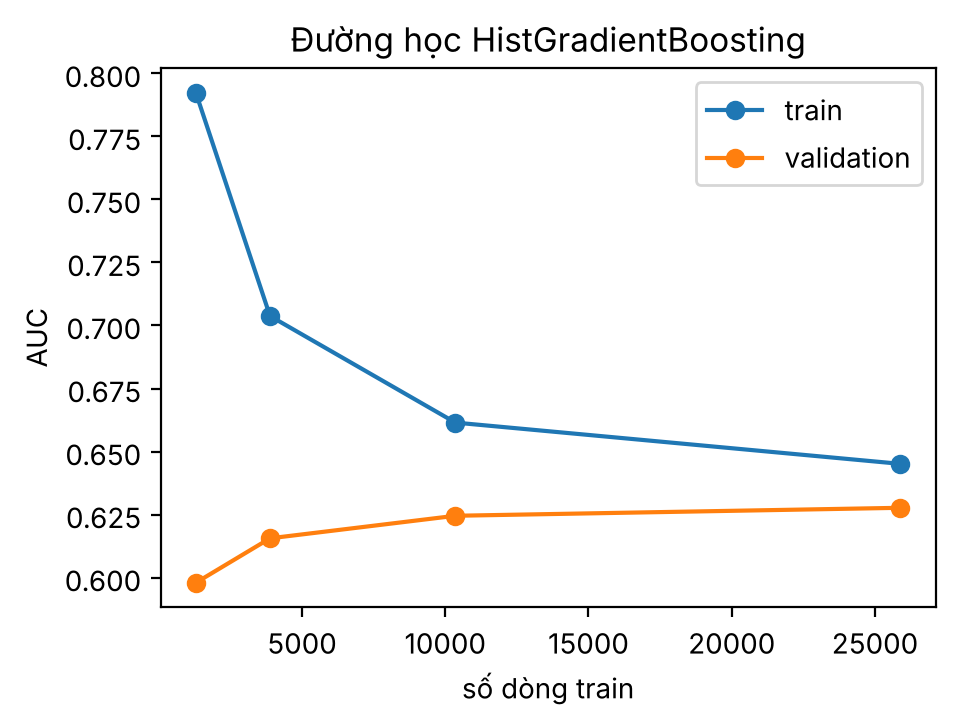

In [9]:
from sklearn.model_selection import learning_curve
sizes, a, b = learning_curve(hgb, X[tr], y[tr], groups=groups[tr], cv=GroupKFold(3),
                             train_sizes=[0.05, 0.15, 0.4, 1.0], scoring='roc_auc', shuffle=True, random_state=1)
plt.figure(figsize=(5, 3.5))
plt.plot(sizes, a.mean(1), 'o-', label='train'); plt.plot(sizes, b.mean(1), 'o-', label='validation')
plt.xlabel('số dòng train'); plt.ylabel('AUC'); plt.legend(); plt.title('Đường học HistGradientBoosting'); plt.show()

## Bước 9. Model dựa vào đặc trưng nào?

Hệ số Logistic Regression (đã chuẩn hóa): dương = làm tăng xác suất đúng. Trong mô phỏng, năng lực tăng sau MỖI lượt luyện, nên "số lượt đã làm kỹ năng" mạnh nhất. Đó là **quy luật của bộ mô phỏng**, chưa chắc đúng với học sinh thật: lý do phải train lại khi có dữ liệu thật.

In [10]:
coef = search.best_estimator_.named_steps['model'].coef_[0]
for n, c in sorted(zip(FEATURE_NAMES, coef), key=lambda kv: -abs(kv[1]))[:8]:
    print(f'{n:22s} {c:+.3f}')

log_n_skill            +0.394
acc_user               +0.178
seen_skill             -0.072
is_review              +0.042
ema_group              +0.034
ema_skill              +0.033
log_n_user             -0.028
last_skill             -0.020


## Bước 10. Lưu và dùng trong app

`python -m app.ml.correctness.train` train trên 2.000 người, lưu `backend/models/correctness/model.joblib` + `manifest.json`. API `GET /api/v1/me/predictions` (bật bằng `PREDICT_ENABLED=1`) nạp file đó và trả xác suất cho từng kỹ năng. Mastery EMA và hệ gợi ý không đổi.

Khi có dữ liệu thật: `python -m app.ml.correctness.dataset --out ../data/correctness/that.jsonl` rồi `python -m app.ml.correctness.train --data ../data/correctness/that.jsonl`.